In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import astropy.units as u 
import astropy.constants as c 

In [3]:
class Body():
    def __init__(self, mass, x_vec, v_vec, name=None, has_units=True):
        self.has_units = has_units
        if self.has_units:
            self.x_vec = x_vec.cgs.value
            self.v_vec = v_vec.cgs.value
            self.mass = mass.cgs.value
        else:
            self.x_vec = x_vec
            self.v_vec = v_vec
            self.mass = mass
        self.name = name
        pass

    def return_vec(self):
        y_vec = np.concatenate((self.x_vec, self.v_vec))
        return y_vec
    
    def return_name(self):
        return self.name
    
    def return_mass(self):
        return self.mass


In [4]:
#here is some mass a user might set up
my_mass = 10 * u.Msun
print(my_mass)
# We can convert this to cgs and then strip the units via

my_mass_stripped = my_mass.cgs.value
print(my_mass_stripped)

10.0 solMass
1.988409870698051e+34


In [5]:
Earth = Body(name='Earth',
             x_vec = np.array([0,1,0])*u.AU,
             v_vec = np.array([0,30,0])*u.km/u.s,
             mass = 1.0*c.M_earth) 

In [6]:
print(Earth.return_vec())

[0.00000000e+00 1.49597871e+13 0.00000000e+00 0.00000000e+00
 3.00000000e+06 0.00000000e+00]


In [7]:
Earth = Body(name='Earth',
             x_vec = np.array([0,1,0])*u.AU,
             v_vec = np.array([0,30,0])*u.km/u.s,
             mass = 1.0*c.M_earth) 
Sun = Body(name='Sun',
           x_vec = np.array([0,0,0])*u.AU,
           v_vec = np.array([0,0,0])*u.km/u.s,
           mass = 1*u.Msun)

bodies = [Earth,Sun]

In [ ]:
class Simulation():
    def __init__(self, bodies):
        self.bodies = bodies
        self.N_bodies = len(self.bodies)
        self.Ndim = 6
        for i in self.bodies:
            self.quant_vec = np.concatenate(np.array([i.return_vec()]))
            self.mass_vec = np.array([i.return_mass()])
            self.name_vec = i.return_name()
    def set_diff_eq(self,calc_diff_eqs,**kwargs):
        self.diff_eq_kwargs = kwargs
        self.calc_diff_eqs = calc_diff_eqs
    def rk4(self,t,dt):
        '''
        RK4 integrator. Calculates the K values and returns a new y vector
        --------------------------------
        Params:
        t: a time. Only used if the diff eq depends on time (gravity doesn't).
        dt: timestep. Non adaptive in this case
        '''
        k1 = dt * self.calc_diff_eqs(t, self.quant_vec,self.mass_vec,**self.diff_eq_kwargs) 
        k2 = dt * self.calc_diff_eqs(t + 0.5*dt, self.quant_vec + 0.5*k1, self.mass_vec, **self.diff_eq_kwargs)
        k3 = dt * self.calc_diff_eqs(t + 0.5*dt, self.quant_vec + 0.5*k2, self.mass_vec, **self.diff_eq_kwargs)
        k4 = dt * self.calc_diff_eqs(t + dt, self.quant_vec + k3, self.mass_vec, **self.diff_eq_kwargs)
        y_new = self.quant_vec + ((k1 + 2*k2 + 2*k3 + k4) / 6.0)

        return y_new
    def run(self,T,dt,t0=0):
        '''
        Method which runs the simulation on a given set of bodies.
        ---------------------
        Params: 
            T: total time (in simulation units) to run the simulation. Can have units or not, just set has_units appropriately.
            dt: timestep (in simulation units) to advance the simulation. Same as above
            t0 (optional): set a non-zero start time to the simulation.

        Returns: 
            None, but leaves an attribute history accessed via 
           'simulation.history' which contains all y vectors for the simulation. 
            These are of shape (Nstep,Nbodies * 6), so the x and y positions of particle 1 are
            simulation.history[:,0], simulation.history[:,1], while the same for particle 2 are
            simulation.history[:,6], simulation.history[:,7]. Velocities are also extractable.
        '''
        
    pass

my_simulation = Simulation(bodies) 

In [12]:
def rk4(t,dt,y,evaluate):
    k1 = dt * evaluate(t, y) 
    k2 = dt * evaluate(t + 0.5*dt, y + 0.5*k1)
    k3 = dt * evaluate(t + 0.5*dt, y + 0.5*k2)
    k4 = dt * evaluate(t + dt, y + k3)

    y_new = y + (1/6.)*(k1+ 2*k2 + 2*k3 + k4)
    return y_new
def evaluate_SHO(t,y,k=1):
    '''
    evaluate the SHO at time t and y=y. 
    Note: this diff eq has no time dependence
    '''
    v = y[1] 
    a = -k**2 * y[0]
    return np.array([v,a])

In [14]:
y_0 = np.array([-5,0]) #initialize oscillator at x = -5, with 0 velocity. 
history = [y_0]
ts = [0]
dt = 0.01
t = 10
nsteps = int(T/dt)
for i in range(nsteps):
    y_new = rk4(t,dt,history[-1],evaluate_SHO)
    history.append(y_new)
    t = ts[-1] + dt
    ts.append(t)
history = np.array(history)
ts = np.array(ts)

In [15]:
print(history)

[[-5.          0.        ]
 [-4.99975     0.04999917]
 [-4.99900003  0.09999333]
 ...
 [ 4.24891709 -2.63565999]
 [ 4.22234848 -2.67801667]
 [ 4.19535765 -2.72010555]]


Text(0.5, 0, 'time')

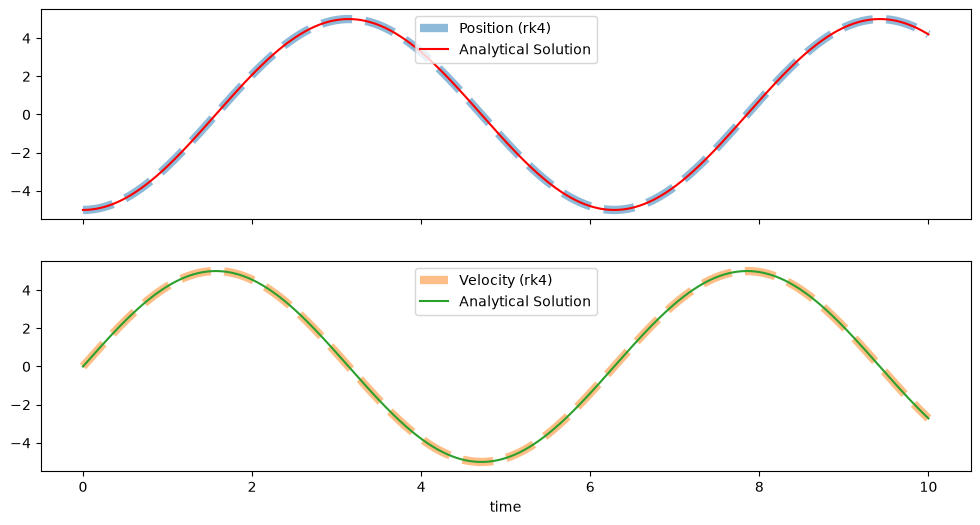

In [16]:
analytical_solution = -5*np.cos(ts)
analytical_velocity = 5*np.sin(ts)
fig, ax = plt.subplots(2,1,figsize=(12,6),sharex=True)
ax[0].plot(ts,history[:,0],color='C0',lw=6,ls='--',label='Position (rk4)',alpha=0.5)
ax[0].plot(ts,analytical_solution,color='r',label='Analytical Solution')
ax[1].plot(ts,history[:,1],color='C1',lw=6,alpha=0.5,ls='--',label='Velocity (rk4)')
ax[1].plot(ts,analytical_velocity,'C2',label='Analytical Solution')
ax[0].legend(loc="upper center")
ax[1].legend(loc="upper center")
ax[-1].set_xlabel('time')

In [19]:
Simulation.run(T=10*u.day,dt=u.hr,t0=0)

TypeError: Simulation.run() missing 1 required positional argument: 'self'